[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C07/E07-1_Lobes_Stabilite_CORRIGE.ipynb)

# Stabilité de coupe en usinage : tracer la frontière la plus sûre

## Le contexte

En fraisage à grande vitesse, la fraise se met parfois à vibrer : c'est le broutement, qui marque la surface et use l'outil. Il apparaît quand la profondeur de passe dépasse une limite qui dépend de la vitesse de broche, de l'outil et de la matière usinée, et cette limite n'est pas constante : elle dessine des lobes, avec des vitesses où l'on peut passer plus profond que la normale. Un atelier de fraisage a relevé 600 essais, avec l'outil (court ou long), la matière, la vitesse de broche, la profondeur axiale de passe, l'avance par dent et le constat : broutement ou non. On voudrait prévoir le broutement avant d'usiner.

La grandeur à prédire est une catégorie, stable ou instable : c'est un problème de classification binaire.

Défi : prédire `instable` et obtenir un F-score macro supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est un séparateur à vaste marge à noyau linéaire, qui trace la frontière plane la plus éloignée des essais des deux classes ; il atteint un F-score macro de 0,740 : à vous de faire mieux, en laissant la frontière se courber. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Lobes_Stabilite.xlsx`, dans le dossier `donnees` du dépôt : 600 essais, 6 colonnes. Une ligne est un essai de fraisage.

| Colonne | Signification | Unité |
|---|---|---|
| `outil` | fraise courte ou longue, selon son porte-à-faux | catégorie |
| `matiere` | matière usinée : acier, aluminium ou titane | catégorie |
| `vitesse_broche_tr_min` | vitesse de broche commandée | tr/min |
| `profondeur_axiale_mm` | profondeur axiale de passe | mm |
| `avance_dent_mm` | avance par dent | mm |
| `instable` | cible : `1` si le broutement est constaté, `0` sinon | 0 ou 1 |

Origine : jeu simulé, selon la théorie du broutement régénératif d'un système à un degré de liberté. Quelques avances ne sont pas consignées. Il enseigne une méthode, et aucune conclusion d'usinage n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la répartition des deux constats avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Lobes_Stabilite.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Lobes_Stabilite.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "instable"
categories = ["outil", "matiere"]
mesures = ["vitesse_broche_tr_min", "profondeur_axiale_mm", "avance_dent_mm"]
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
print(df[cible].value_counts().to_dict())
df.head(3)

dimensions : (600, 6)
cases vides : {'avance_dent_mm': 13}
{0: 315, 1: 285}


,outil,matiere,vitesse_broche_tr_min,profondeur_axiale_mm,avance_dent_mm,instable
0,long,aluminium,16660,1.76,0.080,1
1,court,acier,17090,1.62,0.084,1
2,long,titane,18900,1.24,0.095,0


Lecture du résultat : 600 essais, 6 colonnes. L'avance par dent compte 13 cases vides, qu'il faudra remplir. Les deux constats sont assez équilibrés (285 essais instables sur 600) : l'exactitude a un sens, et le F-score macro compte chaque constat pour autant.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Lobes_Stabilite.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des essais est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. Le tirage est stratifié, pour que les deux constats soient représentés dans les deux bases dans la même proportion.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=GRAINE, stratify=y)
print("apprentissage :", len(X_train), "essais")
print("test :", len(X_test), "essais")

apprentissage : 450 essais
test : 150 essais


### Étape 3 : regarder la frontière sur l'apprentissage

La figure place, pour une même matière, les essais d'apprentissage selon la vitesse de broche et la profondeur de passe, un panneau par outil. Les croix sont les essais instables, les ronds les essais stables.

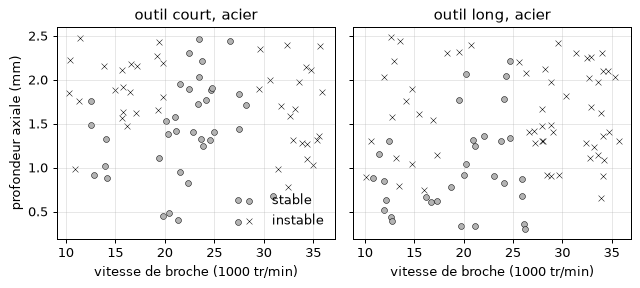

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3), sharey=True)
for ax, outil in zip(axes, ["court", "long"]):
    choix = (X_train["outil"] == outil) & (X_train["matiere"] == "acier")
    for valeur, marque, gris, nom in [(0, "o", "0.7", "stable"), (1, "x", "black", "instable")]:
        k = choix & (y_train == valeur)
        ax.scatter(X_train.loc[k, "vitesse_broche_tr_min"] / 1000, X_train.loc[k, "profondeur_axiale_mm"],
                   s=22, marker=marque, color=gris, edgecolor="black" if marque == "o" else None,
                   linewidth=0.4, label=nom)
    ax.set(title=f"outil {outil}, acier", xlabel="vitesse de broche (1000 tr/min)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("profondeur axiale (mm)")
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Lecture du résultat : les essais stables se tiennent sous une limite de profondeur, mais cette limite change avec la vitesse de broche, et d'un outil à l'autre : elle n'est pas une droite. Une frontière plane, qui sépare les deux classes par un hyperplan, ne pourra en suivre qu'une moyenne. Il faut un modèle capable de courber la frontière, ce que font les noyaux.

### Étape 4 : construire le modèle de départ

Le modèle de départ est celui de la section du livre : un séparateur à vaste marge, qui cherche la frontière laissant la plus grande marge aux essais les plus proches de chaque classe. Avec un noyau linéaire, cette frontière est plane. Un pipeline encode d'abord l'outil et la matière en colonnes 0 ou 1, remplit les avances manquantes par la médiane de l'apprentissage et met les mesures à l'échelle. Il apprend sur `X_train` seul.

In [4]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

preprocessor = make_column_transformer(
    (OneHotEncoder(), categories),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), mesures))
modele = make_pipeline(preprocessor, SVC(kernel="linear"))
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(),
                                                  ['outil', 'matiere']),
                                                 ('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['vitesse_broche_tr_min',
                                                   'profondeur_axiale_mm',
                                                   'avance_dent_mm'])])),
                ('svc', SVC(kernel='linear'))])

### Étape 5 : mesurer sur la base de test

Le modèle prédit les essais qu'il n'a jamais vus. On lit le F-score macro, l'exactitude et le nombre de vecteurs de support, c'est-à-dire d'essais qui tiennent la frontière. Un témoin sans apprentissage, qui répond toujours le constat le plus fréquent, donne le point de comparaison le plus bas.

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

y_pred = modele.predict(X_test)
score_depart = f1_score(y_test, y_pred, average="macro")
temoin = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
score_temoin = f1_score(y_test, temoin.predict(X_test), average="macro")
print(f"F-score macro : {score_depart:.3f}")
print(f"exactitude : {accuracy_score(y_test, y_pred):.3f}")
print(f"F-score macro du témoin (toujours le constat le plus fréquent) : {score_temoin:.3f}")
print(f"vecteurs de support : {int(modele[-1].n_support_.sum())} sur {len(X_train)} essais")

F-score macro : 0.740
exactitude : 0.740
F-score macro du témoin (toujours le constat le plus fréquent) : 0.345
vecteurs de support : 269 sur 450 essais


Lecture du résultat : le F-score macro est de 0,740 pour une exactitude de 0,740, au-dessus du témoin (0,345). La frontière plane s'appuie sur 269 essais sur 450 : une grande part des essais touche la marge, signe que les deux classes se recouvrent pour une droite. C'est ce chiffre, mesuré sur des essais que le modèle n'a jamais vus, que l'on a le droit d'annoncer.

## Pour aller plus loin : courber la frontière avec un noyau, puis régler C et gamma

Le modèle de départ de l'étape 4 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première compare par validation croisée, sur l'apprentissage seul, le noyau linéaire, un noyau polynomial et un noyau gaussien aux réglages par défaut, puis ce dernier avec C et gamma choisis par une grille. Cette dernière variante est mesurée en validation croisée emboîtée : la grille est refaite dans chaque pli. Une forêt aléatoire et un gradient boosting, vus au chapitre 8, sont donnés pour comparaison ; ils ne sont pas candidats, puisque la section porte sur les noyaux. La seconde cellule mesure le modèle retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [6]:
# Solution :
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
grille = GridSearchCV(
    make_pipeline(preprocessor, SVC()),
    param_grid={"svc__C": [1, 10, 100], "svc__gamma": [0.1, 0.3, 1, 3]},
    cv=5, scoring="f1_macro")
candidats = {
    "départ : noyau linéaire": modele,
    "noyau polynomial de degré 3": make_pipeline(preprocessor, SVC(kernel="poly", degree=3)),
    "noyau gaussien, réglages par défaut": make_pipeline(preprocessor, SVC()),
    "noyau gaussien, C et gamma par grille": grille}
comparaison = {
    "forêt aléatoire (chapitre 8)": make_pipeline(
        preprocessor, RandomForestClassifier(n_estimators=200, random_state=GRAINE)),
    "gradient boosting par histogrammes (chapitre 8)": make_pipeline(
        preprocessor, HistGradientBoostingClassifier(random_state=GRAINE))}
notes_cv, notes_comparaison = {}, {}
for nom, pipeline in candidats.items():
    notes = cross_val_score(pipeline, X_train, y_train, cv=plis, scoring="f1_macro")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : F-score macro {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
for nom, pipeline in comparaison.items():
    notes = cross_val_score(pipeline, X_train, y_train, cv=plis, scoring="f1_macro")
    notes_comparaison[nom] = notes.mean()
    print(f"pour comparaison, {nom} : F-score macro {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
# Fin de la solution

départ : noyau linéaire : F-score macro 0.723 +/- 0.043 sur 5 plis
noyau polynomial de degré 3 : F-score macro 0.817 +/- 0.059 sur 5 plis
noyau gaussien, réglages par défaut : F-score macro 0.798 +/- 0.056 sur 5 plis
noyau gaussien, C et gamma par grille : F-score macro 0.861 +/- 0.059 sur 5 plis
modèle retenu par la validation croisée : noyau gaussien, C et gamma par grille
pour comparaison, forêt aléatoire (chapitre 8) : F-score macro 0.910 +/- 0.034 sur 5 plis
pour comparaison, gradient boosting par histogrammes (chapitre 8) : F-score macro 0.922 +/- 0.034 sur 5 plis


In [7]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
f1_retenu = f1_score(y_test, retenu.predict(X_test), average="macro")
print(f"{nom_retenu}, mesuré une fois sur le test : F-score macro {f1_retenu:.3f}")
print(f"gain sur le modèle de départ : {f1_retenu - score_depart:+.3f}")
if hasattr(retenu, "best_params_"):
    print("réglages choisis par la grille :", retenu.best_params_)
# Fin de la solution

noyau gaussien, C et gamma par grille, mesuré une fois sur le test : F-score macro 0.893
gain sur le modèle de départ : +0.153
réglages choisis par la grille : {'svc__C': 100, 'svc__gamma': 0.1}


Lecture du résultat : en validation croisée sur l'apprentissage, le modèle retenu (noyau gaussien, C et gamma par grille) obtient 0,861 contre 0,723 pour le modèle de départ ; mesuré une seule fois sur le test, il passe de 0,740 à 0,893, soit un gain de 0,153. Le réglage C = 100 est à l'extrémité de la grille : une grille plus large serait la suite logique. La forêt aléatoire et le gradient boosting, vus au chapitre 8, font encore mieux en validation croisée (0,910 et 0,922) : le noyau n'est pas la seule bonne réponse, mais il apporte déjà une grande part du gain sur la frontière plane.

## Le score de référence

Le score publié est le F-score macro du modèle de départ de l'étape 4 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [8]:
import hashlib

score = f1_score(y_test, modele.predict(X_test), average="macro")
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE f1_macro = %.3f" % score)

EMPREINTE_TEST = 1d206077ec173cb90b7ae9c7189814da14af0122f3f785959da05515d714e4c6
SCORE_REFERENCE f1_macro = 0.740


## Synthèse

1. Un séparateur à vaste marge cherche la frontière qui laisse la plus grande marge aux essais les plus proches de chaque classe ; seuls ces vecteurs de support la déterminent.
2. Avec un noyau linéaire, la frontière est plane : elle ne peut pas suivre une limite de stabilité en lobes.
3. Un noyau, polynomial ou gaussien, courbe la frontière sans construire explicitement de nouvelles colonnes ; le gaussien est réglé par C, qui arbitre marge et erreurs, et par gamma, qui fixe la portée de chaque essai.
4. Ces réglages et la mise à l'échelle se choisissent sur l'apprentissage, par validation croisée ; une grille de réglages se mesure dans une validation croisée emboîtée, sinon son score est trop optimiste.
5. Le test ne sert qu'une fois, au modèle retenu ; sur 150 essais, un essai de plus ou de moins bien classé déplace l'exactitude de 0,007.